# Inflation and Monthly S&P 500 Returns
*INFO 2950 Phase 3*
**Jaemin Kwon (jk2975) and Mike Zhang (hz727)**  

Neither group member is a native English speaker.

## 1. Introduction

Inflation is often viewed as a risk to stock-market performance, but the relationship is not straightforward. Higher inflation may coincide with rising borrowing costs and pressure on profits, or with stronger demand and earnings. Using publicly available U.S. data from FRED, we examine how inflation relates to monthly S&P 500 price returns. This matters because investors may use inflation as a market signal even when its predictive value is limited.

Our main question is: **Between January 2017 and September 2026, is higher year-over-year headline CPI inflation associated with lower monthly S&P 500 price returns?** We examine both same-month and previous-month inflation. We also compare core inflation with headline inflation and consumer inflation expectations with recent inflation.

Our outcome is the monthly S&P 500 price return, excluding dividends. Previous research supports investigating a negative relationship: Fama and Schwert (1977) found a negative association between stock returns and expected inflation, while Bernanke and Kuttner (2004) highlighted the importance of distinguishing anticipated from unexpected monetary-policy changes. Unlike these studies, our analysis uses observed CPI inflation and focuses on associations rather than causal effects or forecasts.

**Summary of findings.** Both models show weak negative associations, explaining less than 3% of monthly return variation. The slopes are statistically significant under our main HAC specification but not under ordinary OLS inference after adjustment for multiple testing. Sensitivity checks generally preserve the negative direction, although the estimated strength varies. Overall, inflation alone explains little of the variation in monthly stock returns, and our statistical conclusions depend on how uncertainty is estimated.

<div class="page-break"></div>

## 2. Data description and cleaning
### Sources and purpose
We combine the four saved Phase 2 series with one new series for the exploratory interest-rate model. All are distributed through FRED, but they come from different producers. 

| Series | Producer and original purpose | Measure used here |
|---|---|---|
| SP500 | S&P Dow Jones Indices; track large U.S. company stock prices | Daily close, converted to monthly price return |
| CPIAUCNS | Bureau of Labor Statistics; measure consumer price change | Headline CPI-U, not seasonally adjusted |
| CPILFENS | Bureau of Labor Statistics; measure consumer price change excluding food and energy | Core CPI-U, not seasonally adjusted |
| MICH | University of Michigan Surveys of Consumers; measure consumer expectations | Median expected price change over the next 12 months (%) |
| FEDFUNDS | Board of Governors of the Federal Reserve System; report money-market interest rates | Monthly-average effective federal funds rate (%) |

The four original CSV snapshots are retained rather than refreshed, so Phase 3 uses the same data as Phase 2. FEDFUNDS was downloaded for this phase and restricted to the same study window. Original series definitions are available from FRED (S&P Dow Jones Indices, n.d.; BLS, n.d.-a, n.d.-b; University of Michigan, n.d.; Board of Governors, n.d.).

### What one row and each column represent
Each observation (row) represents **one calendar month**. The main file has 116 rows and 13 columns. The lag file adds `previous_headline_yoy_pct` and contains 114 rows.

| Columns | Meaning and units |
|---|---|
| `month_index`, `Year`, `Month`, `date` | Calendar identifiers; month_index = Year × 12 + Month |
| `last_trading_date` | Date of the month's final available trading close |
| `sp500_close` | Closing price-index level, in index points |
| `sp500_return_pct` | Change from the previous month-end close, in percent |
| `headline_cpi`, `core_cpi` | CPI index levels; 1982-1984 = 100 |
| `headline_yoy_pct`, `core_yoy_pct` | Change from the same month one year earlier, in percent |
| `expected_inflation_pct` | Consumers' median expected price change over the next year, in percent |
| `fedfunds_pct` | Monthly-average effective federal funds rate, in percent |

A one-unit difference in any rate means **one percentage point**. Stock returns cover one month; headline and core CPI inflation describe price changes over the preceding twelve months, while consumer expectations refer to the following twelve months.

<div class="page-break"></div>

### Cleaning choices and reproducibility
The separate [**Phase 3 data-cleaning notebook**](https://github.com/jkwon128/INFO2950-Project/blob/phase3-draft-2026-11-05/phase3/Phase3_Data_Cleaning.ipynb) documents the cleaning steps and exports the [processed datasets](https://github.com/jkwon128/INFO2950-Project/tree/phase3-draft-2026-11-05/phase3/data/processed) used in our analysis. The [raw CSV files](https://github.com/jkwon128/INFO2950-Project/tree/phase3-draft-2026-11-05/phase3/data/raw) are also available in the repository. To reproduce the results, run the cleaning notebook before the main analysis notebook.

We remove 96 daily records without reported stock closing prices and select the last available trading-day close in each month. Monthly S&P 500 returns are calculated as `100 × (current close / previous close − 1)`. Headline and core inflation are calculated as `100 × (current CPI / CPI twelve months earlier − 1)`, using calendar-month joins rather than row positions. We then merge the series, restrict the data to the study period, and export the analysis samples. **No missing values are imputed.**

| Sample | Months | Reason for the difference |
|---|---:|---|
| Candidate window | 117 | January 2017-September 2026 |
| Same-month main model | 116 | October 2025 CPI is missing |
| Previous-month main model | 114 | Also excludes January 2017 and November 2025 |
| Expectations comparison | 115 | September 2026 expectations are unavailable in our snapshot |
| Same-month model without extremes | 114 | Removes March and April 2020 |
| Previous-month model without extremes | 112 | Removes March and April 2020 |
| Interest-rate extension | 116 | Rate is available for every main-sample month |

The January 2017–September 2026 window follows our Phase 2 research scope and the saved source snapshots. We do not interpret it as a random sample of all market history. The lag is constructed **within the Phase 2 main sample**, as planned. January 2017 therefore has no preceding month in that sample, even though December 2016 CPI exists in the raw data. November 2025 has no October CPI. We retain this restriction rather than changing the planned sample after seeing the results.

### Reliability, collection, and people represented
The sources have documented definitions and identifiable producers, making the measures traceable. This does not mean they measure the same population or are free of error. BLS samples prices and constructs an aggregate urban-consumer index; a household's own purchases may differ from that basket (BLS, n.d.-c). The S&P 500 represents large publicly traded U.S. companies and excludes dividends. Neither series describes every household or investment.

The October 2025 CPI gap reflects the shutdown-related interruption documented by BLS (2025). Dropping it avoids inventing an inflation rate, but leaves uncertainty about the association that would have been observed that month. Consumer expectations are survey responses summarized by a median, which hides disagreement and can be affected by participation and reporting differences.

We use only published aggregates and no individual identifiers. We did not contact participants or independently verify their original consent procedures. The dataset description follows the questions proposed by Gebru et al. (2021). The saved source files make our calculations reproducible, although a fresh download later may contain revisions or different coverage.

<div class="page-break"></div>

## 3. Preregistration statements
### Statement 1: Same-month headline inflation and returns
**Hypothesis:** Higher year-over-year headline inflation is associated with lower same-month S&P 500 price returns.

**Planned analysis:** Fit a simple linear regression with an intercept using all 116 eligible months. The predictor is `headline_yoy_pct`; the outcome is `sp500_return_pct`. Report the sample size, intercept, slope, R², and a scatterplot with the fitted line. The slope measures percentage points of monthly return per percentage point of inflation.

Higher inflation could coincide with higher costs or expected policy tightening, motivating the negative direction. Fama and Schwert (1977) provide historical context, although their measures and period differ from ours. Stronger demand could work in the opposite direction, so the hypothesis is a possibility to investigate rather than a rule we assume.

### Statement 2: Previous-month headline inflation and returns
**Hypothesis:** Higher year-over-year headline inflation in the previous calendar month is associated with lower S&P 500 price returns in the current month.

**Planned analysis:** Fit the same type of regression using `previous_headline_yoy_pct` and the planned 114-month sample. The predictor is matched by calendar month. Report the same quantities as in Statement 1. This asks whether the association also appears when inflation is measured one calendar month earlier, a useful timing comparison because the previous month's CPI is usually released during the current return month.

The two analyses are closely related, not independent replications or a formal comparison of timing effects. The CPI release schedule (BLS, n.d.-d) means that even the lagged model does not exclusively use information available at the beginning of the return month. A null result would also matter: it would challenge the assumption that inflation is a useful standalone signal for monthly returns.

### Analytical Approach and Robustness Checks

We examine the relationship between monthly S&P 500 returns and headline CPI inflation using same-month and previous-month regression models, following our final Phase 2 research plan. Statistical significance is assessed using calendar-aware HAC standard errors and Holm correction, with conventional OLS and alternative lag specifications for comparison. These inferential methods were introduced after Phase 2, during which the same-month association had already been examined.

To assess robustness, we exclude the March–April 2020 market extremes, compare models using a common sample, and examine the federal funds rate as an additional predictor. We also conduct a post-hoc sensitivity check excluding three influential observations identified using Cook's distance. These supplementary analyses are exploratory.

<div class="page-break"></div>

## 4. Data analysis
### Load the cleaned data
The report starts with files exported by the separate cleaning notebook. Download the entire Phase 3 directory (or clone the repository) before running; `data/processed` is relative to the notebook's working directory. These files already contain the required columns and samples. The assertions check the inputs; they do not change observations or fill missing values.

In [1]:
from importlib.util import find_spec

if find_spec("statsmodels") is None:
    get_ipython().run_line_magic("pip", 'install -q "statsmodels>=0.14.5,<0.16"')

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.linear_model import LinearRegression
from scipy.stats import norm
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from IPython.display import display

DATA = Path("data/processed")
names = ["main", "lag", "same_common", "main_no_extremes",
         "lag_no_extremes", "expectations", "interest"]
if not DATA.is_dir():
    raise FileNotFoundError("Missing data/processed. Download the Phase 3 folder and run the separate data-cleaning notebook first.")
samples = {name: pd.read_csv(DATA / f"{name}.csv", parse_dates=["date"])
           for name in names}
main, lagged = samples["main"], samples["lag"]
assert len(main) == 116 and len(lagged) == 114
for frame in samples.values():
    assert not frame.month_index.duplicated().any()
    assert frame[["sp500_return_pct", "headline_yoy_pct"]].notna().all().all()
plt.rcParams.update({"figure.figsize": (8, 3.5), "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
print("Loaded seven prepared samples; main n=116, lagged n=114.")

Loaded seven prepared samples; main n=116, lagged n=114.


### Typical values and spread
Table 1 puts the slopes into context. All four variables are percentages, but stock returns cover one month, CPI inflation looks backward twelve months, and expectations refer to the next twelve months.

In [3]:
variables = ["sp500_return_pct", "headline_yoy_pct",
             "core_yoy_pct", "expected_inflation_pct"]
summary = main[variables].agg(["count", "mean", "std", "min", "max"]).T
summary.index = ["Monthly return", "Headline inflation",
                 "Core inflation", "Expected inflation"]
formatted_summary = summary.copy()
formatted_summary["count"] = formatted_summary["count"].map(lambda v: f"{int(v)}")
for col in ["mean", "std", "min", "max"]:
    formatted_summary[col] = formatted_summary[col].map(lambda v: f"{v:.3f}")
display(formatted_summary.rename(columns={"count": "n", "mean": "Mean", "std": "SD",
                                         "min": "Min", "max": "Max"}))

,n,Mean,SD,Min,Max
Monthly return,116,1.146,4.491,-12.512,12.684
Headline inflation,116,3.351,2.040,0.118,9.060
Core inflation,116,3.150,1.468,1.187,6.631
Expected inflation,115,3.528,1.025,2.100,6.600


**Table 1.** Returns average 1.146%, with a standard deviation of 4.491 percentage points. They range from -12.512% to 12.684%, so there is substantial variation to explain. Headline inflation averages 3.351% and ranges from 0.118% to 9.060%. Expectations use 115 observations; the other summaries use 116.

<div class="page-break"></div>

### The time pattern behind the models
Figure 1 shows how inflation and monthly price returns changed over time. The upper panel follows inflation conditions; the lower panel shows the return outcome on its own scale. October 2025 is left as a gap.

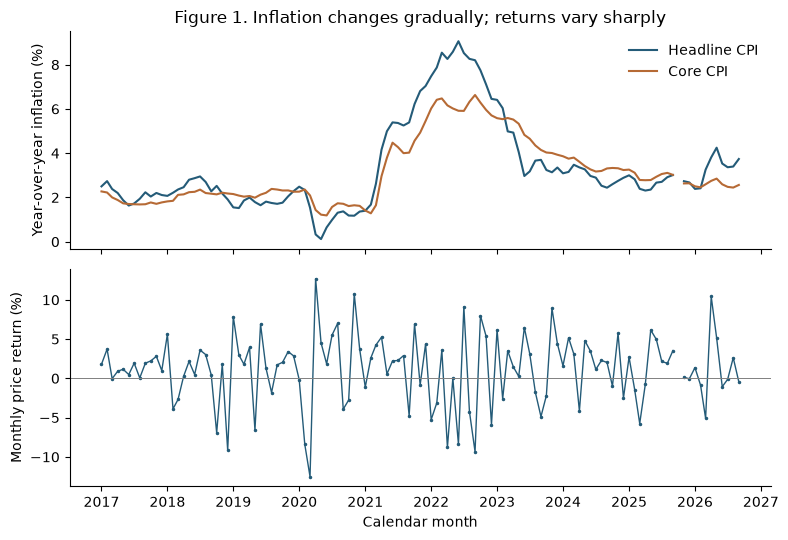

In [4]:
# Reindex only the plotted series so lines do not bridge the missing month.
dates = pd.date_range("2017-01-01", "2026-09-01", freq="MS")
plot_data = main.set_index("date").reindex(dates)
fig, axes = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True)
for column, label, color in [
    ("headline_yoy_pct", "Headline CPI", "#245b78"),
    ("core_yoy_pct", "Core CPI", "#b66a35")]:
    axes[0].plot(plot_data.index, plot_data[column], label=label, color=color)
axes[0].set_ylabel("Year-over-year inflation (%)")
axes[0].legend(frameon=False)
axes[0].set_title("Figure 1. Inflation changes gradually; returns vary sharply")
axes[1].plot(plot_data.index, plot_data.sp500_return_pct,
             color="#245b78", linewidth=1, marker=".", markersize=3)
axes[1].axhline(0, color="gray", linewidth=0.7)
axes[1].set_ylabel("Monthly price return (%)")
axes[1].set_xlabel("Calendar month")
plt.tight_layout()
plt.show()

The largest loss and gain occur in March and April 2020. Inflation reaches its peak later, in June 2022. Returns move much more sharply than inflation, so a straight line is unlikely to explain most of their movement. We keep the 2020 observations in both main models and check their influence separately below.

<div class="page-break"></div>

### Analysis 1: Same-month inflation
We first fit the regression specified in Statement 1. `LinearRegression` includes an intercept by default. The fitted line minimizes the sum of squared differences between observed and fitted monthly returns.

n = 116
Return = 2.316 -0.349 × inflation
R-squared = 0.0252
In-sample RMSE = 4.415 percentage points


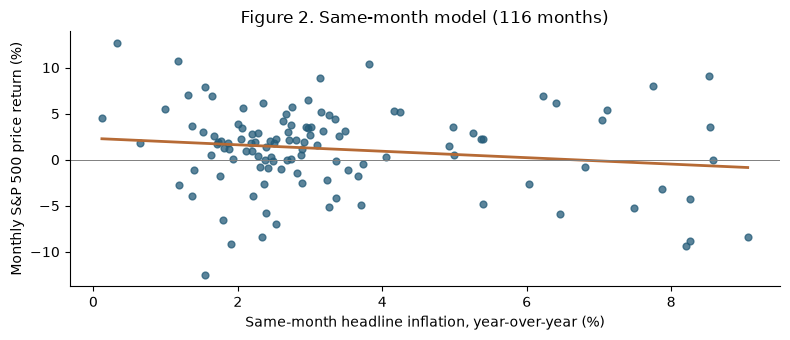

In [5]:
x1 = "headline_yoy_pct"
y = "sp500_return_pct"
model1 = LinearRegression().fit(main[[x1]], main[y])
fitted1 = model1.predict(main[[x1]])
residual1 = main[y].to_numpy() - fitted1
print(f"n = {len(main)}")
print(f"Return = {model1.intercept_:.3f} {model1.coef_[0]:+.3f} × inflation")
print(f"R-squared = {model1.score(main[[x1]], main[y]):.4f}")
print(f"In-sample RMSE = {np.sqrt(np.mean(residual1**2)):.3f} percentage points")

fig, ax = plt.subplots()
ax.scatter(main[x1], main[y], s=24, alpha=0.75, color="#245b78")
grid = pd.DataFrame({x1: np.linspace(main[x1].min(), main[x1].max(), 100)})
ax.plot(grid[x1], model1.predict(grid), color="#b66a35", linewidth=2)
ax.axhline(0, color="gray", linewidth=0.7)
ax.set(xlabel="Same-month headline inflation, year-over-year (%)",
       ylabel="Monthly S&P 500 price return (%)",
       title="Figure 2. Same-month model (116 months)")
plt.tight_layout()
plt.show()

**Summarizing.** A one percentage point higher inflation rate is associated with about **0.349 percentage points lower monthly return**. The sign agrees with the hypothesis, but R² = 0.0252 means the line explains only about 2.5% of observed return variation. Figure 2 shows a wide spread of gains and losses around the line. The intercept, 2.316%, is the fitted return at zero inflation, slightly below the observed inflation range; it is not a guaranteed baseline return.

<div class="page-break"></div>

### Analysis 2: Previous-month inflation
The second regression uses the previous calendar month's inflation. Its 114 rows follow the original sample rule; the lag was prepared in the cleaning notebook and is not a row-wise shift across the missing month.

n = 114
Return = 2.387 -0.369 × prior inflation
R-squared = 0.0282
In-sample RMSE = 4.445 percentage points


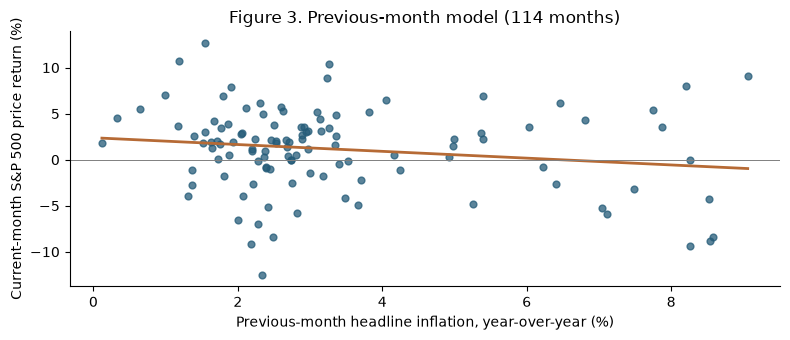

In [6]:
x2 = "previous_headline_yoy_pct"
model2 = LinearRegression().fit(lagged[[x2]], lagged[y])
fitted2 = model2.predict(lagged[[x2]])
residual2 = lagged[y].to_numpy() - fitted2
print(f"n = {len(lagged)}")
print(f"Return = {model2.intercept_:.3f} {model2.coef_[0]:+.3f} × prior inflation")
print(f"R-squared = {model2.score(lagged[[x2]], lagged[y]):.4f}")
print(f"In-sample RMSE = {np.sqrt(np.mean(residual2**2)):.3f} percentage points")

fig, ax = plt.subplots()
ax.scatter(lagged[x2], lagged[y], s=24, alpha=0.75, color="#245b78")
grid = pd.DataFrame({x2: np.linspace(lagged[x2].min(), lagged[x2].max(), 100)})
ax.plot(grid[x2], model2.predict(grid), color="#b66a35", linewidth=2)
ax.axhline(0, color="gray", linewidth=0.7)
ax.set(xlabel="Previous-month headline inflation, year-over-year (%)",
       ylabel="Current-month S&P 500 price return (%)",
       title="Figure 3. Previous-month model (114 months)")
plt.tight_layout()
plt.show()

**Summarizing.** A one percentage point higher previous-month inflation rate is associated with about **0.369 percentage points lower current-month return**. The model explains **2.8%** of return variation (R² = 0.0282), close to the first model's 2.5%. Inflation often changes gradually from one month to the next, so these similar results are not surprising. The small R² difference does not show that the lagged model forecasts better, especially since it uses two fewer months.

<div class="page-break"></div>

### Predicting and examining unusual observations
Table 2 compares model-fitted returns at 2% and 6% inflation. Both values lie within the data range. These values show the average returns given by the fitted lines. They are not forecasts available at the start of a month.

In [7]:
prediction_rows = []
for label, model, x in [("Same month", model1, x1),
                         ("Previous month", model2, x2)]:
    values = model.predict(pd.DataFrame({x: [2.0, 6.0]}))
    prediction_rows.append({"Model": label, "At 2% inflation": values[0],
                            "At 6% inflation": values[1],
                            "Difference (6% - 2%)": values[1] - values[0]})
display(pd.DataFrame(prediction_rows).set_index("Model").round(3))

,At 2% inflation,At 6% inflation,Difference (6% - 2%)
Model,,,
Same month,1.618,0.221,-1.397
Previous month,1.648,0.170,-1.478


**Table 2.** At 2% inflation, the same-month model gives a fitted return of 1.618%; at 6%, it gives 0.221%. The difference is about 1.397 percentage points. The previous-month model gives 1.648% and 0.170%. For comparison, the root mean squared error (RMSE) is about 4.4 percentage points for each model. Actual monthly returns often fall far from the fitted line. These examples illustrate the equations; we have not tested predictions on future months.

**Outliers and oddities.** A large return does not necessarily have the most influence on the line. An unusually high or low inflation value can matter too. We use Cook's distance to identify influential observations in the same-month model.

In [8]:
ols1 = sm.OLS(main[y], sm.add_constant(main[[x1]])).fit()
ols2 = sm.OLS(lagged[y], sm.add_constant(lagged[[x2]])).fit()
influence = main[["date", x1, y]].copy()
influence["Residual (pp)"] = residual1
influence["Cook distance"] = ols1.get_influence().cooks_distance[0]
top_influence = influence.nlargest(3, "Cook distance").copy()
top_influence["date"] = top_influence["date"].dt.strftime("%Y-%m")
influence_display = top_influence.rename(columns={
    "date": "Month", x1: "Headline CPI inflation (%)", y: "S&P 500 return (%)",
    "Residual (pp)": "Residual (pp)", "Cook distance": "Cook's D"
}).set_index("Month")
display(influence_display.style.format("{:.3f}"))
assert np.allclose(ols1.params, [model1.intercept_, model1.coef_[0]])
assert np.allclose(ols2.params, [model2.intercept_, model2.coef_[0]])

,Headline CPI inflation (%),S&P 500 return (%),Residual (pp),Cook's D
Month,,,,
2022-07,8.525,9.112,9.773,0.178
2022-06,9.060,-8.392,-7.544,0.129
2022-09,8.202,-9.340,-8.791,0.127


**Table 3.** July, June, and September 2022 have the largest Cook's distances. Cook's D measures how much a fitted regression can change when an observation is removed; a commonly used screening reference is 4/n (about 0.034 here), not a definitive cutoff (Cook, 1977). Each combines high inflation with a large positive or negative return. The result motivates a separate exploratory sensitivity check beyond the 2020 crash and rebound. We keep these months in the analysis: influence alone is not a reason to remove a real observation.

<div class="page-break"></div>

### Residual checks for both return models
Following Phase 2 feedback, we examine time dependence before interpreting statistical significance. Figure 4 checks both return regressions directly. The upper panels compare residuals with fitted returns; the lower panels keep calendar order and show gaps where a model has no observation.

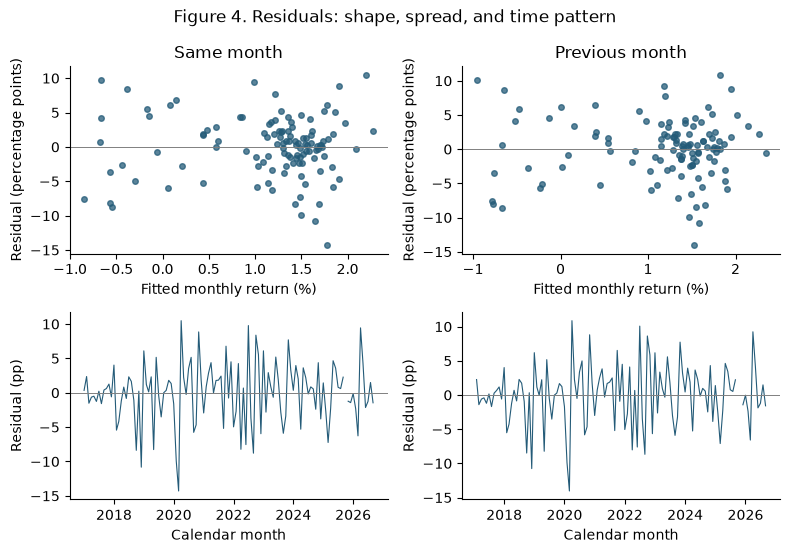

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(8, 5.6))
diagnostic_models = [("Same month", main, fitted1, residual1),
                     ("Previous month", lagged, fitted2, residual2)]
for j, (label, frame, fitted, residual) in enumerate(diagnostic_models):
    axes[0, j].scatter(fitted, residual, s=16, alpha=0.75, color="#245b78")
    axes[0, j].set(title=label, xlabel="Fitted monthly return (%)",
                   ylabel="Residual (percentage points)")
    r = pd.Series(residual, index=frame.date).reindex(dates)
    axes[1, j].plot(r.index, r, linewidth=0.8, color="#245b78")
    axes[1, j].set(xlabel="Calendar month", ylabel="Residual (pp)")
    axes[1, j].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[1, j].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    for i in range(2):
        axes[i, j].axhline(0, color="gray", linewidth=0.7)
fig.suptitle("Figure 4. Residuals: shape, spread, and time pattern")
plt.tight_layout()
plt.show()

The residuals are especially large around the 2020 crash and rebound, and their spread changes over time. The upper panels do not show an obvious curve, but they also do not establish that the errors have constant variance. We next check whether residuals in nearby months are related. The calculation uses actual calendar gaps, so September and November 2025 are not treated as consecutive months.

<div class="page-break"></div>

### Residual correlations at calendar lags
We compare only pairs separated by the stated number of calendar months. Pair counts differ because the samples contain gaps. These correlations are descriptive checks rather than formal tests of independence.

In [10]:
def residual_pairs(frame, residual, lag):
    series = pd.Series(np.asarray(residual), index=frame.month_index)
    earlier = series.copy()
    earlier.index = earlier.index + lag
    pairs = pd.concat([series, earlier], axis=1).dropna()
    return pairs.iloc[:, 0].corr(pairs.iloc[:, 1]), len(pairs)

rows = []
for label, frame, fitted, residual in diagnostic_models:
    for months in [1, 3, 6, 12]:
        correlation, count = residual_pairs(frame, residual, months)
        rows.append({"Model": label, "Lag (months)": months,
                     "Residual correlation": correlation, "Pairs": count})
display(pd.DataFrame(rows).round(3))

,Model,Lag (months),Residual correlation,Pairs
0,Same month,1,-0.167,114
1,Same month,3,0.028,112
2,Same month,6,-0.094,109
3,Same month,12,0.057,104
4,Previous month,1,-0.174,112
5,Previous month,3,0.029,109
6,Previous month,6,-0.091,106
7,Previous month,12,0.068,102


**Table 4.** The one-month residual correlations are -0.167 and -0.174. A positive error tends to be followed by a somewhat lower error, and vice versa, although the relationship is modest. The other correlations shown are smaller in absolute value. These checks do not establish independence, and the changing spread seen in Figure 4 also matters for uncertainty.

## 5. Evaluation of significance
### How we calculate uncertainty
Ordinary OLS standard errors assume that errors are uncorrelated and have constant variance. To allow for changing variance and relationships between nearby months, we use **heteroskedasticity and autocorrelation consistent (HAC)** standard errors, following the Bartlett-weighted approach of Newey and West (1987). The regression coefficients stay the same; the standard errors change.

Our main calculation includes pairs up to **three calendar months** apart, with Bartlett weights that give closer pairs more weight. We also check zero, six, and twelve months because three months is a choice, not a known cutoff for dependence. Zero-lag HAC adjusts for changing variance without using cross-month score covariances. Missing months contribute zero to the score calculation, without filling in their CPI or return values. This follows the approach to missing observations discussed by Datta and Du (2012). The calendar adjustment matters because the standard statsmodels routine assumes equally spaced rows.

We apply a sample-size correction to the covariance and use a normal approximation for p-values and confidence intervals. With only 114-116 observations, these approximations deserve caution. We show ordinary OLS results alongside HAC so the reader can see whether the choice changes the conclusion.

### Calculate calendar-aware HAC uncertainty
The function below builds the covariance from each observed month's residual and predictor values. Missing months contribute no scores, and actual month differences determine the lag weights.

In [11]:
def calendar_hac(frame, predictors, max_lag=3):
    """OLS covariance with Bartlett weights at actual calendar-month lags."""
    X = np.column_stack([np.ones(len(frame)), frame[predictors].to_numpy()])
    y = frame.sp500_return_pct.to_numpy()
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    residual = y - X @ beta
    scores = X * residual[:, None]
    months = frame.month_index.to_numpy(dtype=int)
    # Zero score contributions preserve gaps; no missing data values are filled.
    grid = np.zeros((months.max() - months.min() + 1, X.shape[1]))
    grid[months - months.min()] = scores
    meat = grid.T @ grid
    for lag in range(1, max_lag + 1):
        weight = 1 - lag / (max_lag + 1)
        cross = grid[lag:].T @ grid[:-lag]
        meat += weight * (cross + cross.T)
    bread = np.linalg.inv(X.T @ X)
    n, k = X.shape
    covariance = n / (n - k) * bread @ meat @ bread
    se = np.sqrt(np.diag(covariance))
    return beta, se, covariance

For each slope, we divide the estimate by its HAC standard error to obtain the test statistic. We use a one-sided test because the hypotheses specify a **negative** association. At a zero slope, the p-value measures the probability of a statistic this negative or more negative, under the model assumptions. It is not the probability that the null hypothesis is true.

There are two main tests, so we apply Holm's (1979) correction at a family-wise 5% level. Family-wise here means controlling the chance of at least one false rejection across the two tests. This accounts for testing both slopes and does not require the tests to be independent, although it still relies on valid p-values. The confidence intervals shown below are individual two-sided 95% intervals; they do not give simultaneous 95% coverage for both slopes.

<div class="page-break"></div>

### Main significance results
Table 5 reports the slopes, standard errors, confidence intervals, and one-sided p-values. Table 6 applies the two-test correction and states the decisions.

In [12]:
specs = [("Same month", main, x1), ("Previous month", lagged, x2)]
inference_rows = []
for label, frame, predictor in specs:
    beta, se, covariance = calendar_hac(frame, [predictor], max_lag=3)
    low, high = beta[1] + np.array([-1, 1]) * norm.ppf(0.975) * se[1]
    inference_rows.append({"Model": label, "Slope": beta[1],
        "HAC SE": se[1], "95% lower": low, "95% upper": high,
        "One-sided p": norm.cdf(beta[1] / se[1])})
inference = pd.DataFrame(inference_rows).set_index("Model")
reject, adjusted, _, _ = multipletests(
    inference["One-sided p"], alpha=0.05, method="holm")
display(inference.round(4))
decisions = pd.DataFrame({"Holm-adjusted p": adjusted,
    "Decision": np.where(reject, "Reject H0", "Fail to reject H0")},
    index=inference.index)
display(decisions.round(4))

,Slope,HAC SE,95% lower,95% upper,One-sided p
Model,,,,,
Same month,-0.3493,0.1637,-0.6701,-0.0284,0.0164
Previous month,-0.3694,0.1594,-0.6818,-0.0570,0.0102


,Holm-adjusted p,Decision
Model,,
Same month,0.0205,Reject H0
Previous month,0.0205,Reject H0


**Tables 5-6.** The same-month slope is -0.349, with a 95% confidence interval of **[-0.670, -0.028]**. The previous-month slope is -0.369, with an interval of **[-0.682, -0.057]**. The one-sided p-values are 0.0164 and 0.0102. After Holm's correction, both are **0.0205**.

We therefore **reject both nonnegative-slope null hypotheses at the family-wise 5% level under this HAC calculation**. The negative estimates support the directions we proposed in Phase 2. However, a statistically significant slope can still explain very little: both R² values remain below 0.03.

<div class="page-break"></div>

### How sensitive are the significance decisions?
We repeat the covariance calculation with zero, six, and twelve calendar lags. Zero-lag HAC adjusts for heteroskedasticity but omits cross-month covariance terms. We also show the ordinary OLS t-test, using the same negative alternative and the same Holm adjustment. This comparison changes the uncertainty calculation, not the samples or fitted slopes.

In [13]:
uncertainty_rows = []
for bandwidth in [0, 3, 6, 12]:
    pvalues, errors = [], []
    for label, frame, predictor in specs:
        beta, se, _ = calendar_hac(frame, [predictor], bandwidth)
        pvalues.append(norm.cdf(beta[1] / se[1]))
        errors.append(se[1])
    adjusted = multipletests(pvalues, method="holm")[1]
    for j, (label, _, _) in enumerate(specs):
        uncertainty_rows.append({"Method": f"HAC, {bandwidth} months",
            "Model": label, "SE": errors[j], "One-sided p": pvalues[j],
            "Holm p": adjusted[j]})
ordinary_p = [ols1.pvalues.iloc[1] / 2, ols2.pvalues.iloc[1] / 2]
ordinary_adjusted = multipletests(ordinary_p, method="holm")[1]
for j, (label, model) in enumerate([("Same month", ols1),
                                   ("Previous month", ols2)]):
    uncertainty_rows.append({"Method": "Ordinary OLS t-test", "Model": label,
        "SE": model.bse.iloc[1], "One-sided p": ordinary_p[j],
        "Holm p": ordinary_adjusted[j]})
display(pd.DataFrame(uncertainty_rows).round(4))

,Method,Model,SE,One-sided p,Holm p
0,"HAC, 0 months",Same month,0.2690,0.0971,0.1662
1,"HAC, 0 months",Previous month,0.2668,0.0831,0.1662
2,"HAC, 3 months",Same month,0.1637,0.0164,0.0205
3,"HAC, 3 months",Previous month,0.1594,0.0102,0.0205
4,"HAC, 6 months",Same month,0.1488,0.0095,0.0132
5,"HAC, 6 months",Previous month,0.1491,0.0066,0.0132
6,"HAC, 12 months",Same month,0.1172,0.0014,0.0022
7,"HAC, 12 months",Previous month,0.1207,0.0011,0.0022
8,Ordinary OLS t-test,Same month,0.2036,0.0445,0.0744
9,Ordinary OLS t-test,Previous month,0.2051,0.0372,0.0744


**Table 7.** The main three-month HAC calculation rejects both nonnegative-slope null hypotheses after Holm adjustment; the six- and twelve-month versions do too. Zero-lag HAC gives **larger** standard errors (about 0.269 and 0.267), whereas three-month HAC gives smaller standard errors (about 0.164 and 0.159). Ordinary OLS gives Holm-adjusted p-values of about **0.0744**, above 0.05. The fitted slopes have not changed; the estimated uncertainty has.

The negative one-month residual correlations in Table 4 are consistent with some negative time dependence, but **residual correlation alone does not determine the slope's HAC standard error**: the covariance uses predictor-weighted residuals. We therefore cannot attribute the difference to the lag-one correlation by itself. Our evidence for statistical significance is sensitive to the uncertainty specification, and neither approach establishes forecasting usefulness. The three-month HAC analysis is a **Phase 3 method addition**, not a fully preregistered procedure.

<div class="page-break"></div>

## 6. Exploratory checks
### Do the 2020 extremes drive the slopes?
The reviewer suggested excluding the 2020 extremes while retaining the original models. We remove **March and April 2020**, the crash and rebound identified in Phase 2, and refit both lines. We also fit the same-month model on the lagged model's 114 months, so that a difference in sample composition does not get confused with a timing difference.

In [14]:
def describe_fit(label, frame, predictors):
    model = LinearRegression().fit(frame[predictors], frame[y])
    return {"Model / sample": label, "n": len(frame),
            "Intercept": model.intercept_, "Inflation slope": model.coef_[0],
            "R-squared": model.score(frame[predictors], frame[y])}

checks = [
    describe_fit("Same month: main", main, [x1]),
    describe_fit("Same month: no Mar-Apr 2020", samples["main_no_extremes"], [x1]),
    describe_fit("Previous month: main", lagged, [x2]),
    describe_fit("Previous month: no Mar-Apr 2020", samples["lag_no_extremes"], [x2]),
    describe_fit("Same month: common 114 months", samples["same_common"], [x1])]
check_table = pd.DataFrame(checks).set_index("Model / sample")
display(check_table.round(4))

,n,Intercept,Inflation slope,R-squared
Model / sample,,,,
Same month: main,116,2.3163,-0.3493,0.0252
Same month: no Mar-Apr 2020,114,2.3087,-0.3372,0.0265
Previous month: main,114,2.3869,-0.3694,0.0282
Previous month: no Mar-Apr 2020,112,2.3771,-0.3581,0.0304
Same month: common 114 months,114,2.3274,-0.3503,0.0253


**Table 8.** Without March and April 2020, the same-month slope changes from -0.349 to **-0.337**, and the previous-month slope changes from -0.369 to **-0.358**. Both stay negative and close to their original values. R² is still low, at about 2.6% and 3.0%. The two extreme months do not appear to drive the fitted relationships. This check concerns the slopes and R², not whether the p-values stay the same.

Using the same 114 months for both models gives a same-month slope of **-0.350** and R² of **0.0253**, again close to the original result. The sample difference therefore explains little of the difference between the two models. We have not formally tested whether their slopes differ.

### Do the most influential 2022 observations change the result?
Table 3 identified June, July, and September 2022 as the three most influential observations in the **same-month** model. As a **post-hoc exploratory check**, we exclude those same three calendar months from *both* models and refit them. We choose these months using Cook's distance from the original same-month model, rather than searching for an exclusion that improves statistical significance. These are real economic observations, so this check is not a justification for removing them from the primary analysis.

In [15]:
# Use the three dates already identified in Table 3, identically for both models.
influential_months = pd.to_datetime(top_influence["date"]).dt.to_period("M")
influential_months = set(influential_months)
main_without_influential = main.loc[~main["date"].dt.to_period("M").isin(influential_months)]
lag_without_influential = lagged.loc[~lagged["date"].dt.to_period("M").isin(influential_months)]
influence_checks = pd.DataFrame([
    describe_fit("Same month: full sample", main, [x1]),
    describe_fit("Same month: exclude three 2022 months", main_without_influential, [x1]),
    describe_fit("Previous month: full sample", lagged, [x2]),
    describe_fit("Previous month: exclude same three months", lag_without_influential, [x2])
]).set_index("Model / sample")
display(influence_checks.style.format({"n": "{:.0f}", "Intercept": "{:.3f}",
                                      "Inflation slope": "{:.3f}", "R-squared": "{:.4f}"}))
print("Excluded months:", ", ".join(str(m) for m in sorted(influential_months)))

,n,Intercept,Inflation slope,R-squared
Model / sample,,,,
Same month: full sample,116,2.316,-0.349,0.0252
Same month: exclude three 2022 months,113,2.080,-0.258,0.0127
Previous month: full sample,114,2.387,-0.369,0.0282
Previous month: exclude same three months,111,2.232,-0.304,0.0176


Excluded months: 2022-06, 2022-07, 2022-09


**Table 8a (additional exploratory sensitivity check).** Excluding June, July, and September 2022 reduces the same-month slope from **-0.349 to -0.258** (R² from **0.0252 to 0.0127**) and the previous-month slope from **-0.369 to -0.304** (R² from **0.0282 to 0.0176**). Both slopes remain negative, but their magnitudes shrink. This suggests that part of the estimated association is influenced by a few high-inflation months. We do **not** use these post-hoc exclusions to claim renewed statistical significance or replace the preregistered samples.

### Does adding an interest rate explain more?
Feedback on Phase 2 suggested interest rates as an additional exploratory analysis. We add the **same-month monthly-average effective federal funds rate** to the first model. The sample remains 116 months, so the R² comparison uses identical observations. We use this one measure to keep the extension focused.

Bernanke and Kuttner (2004) study stock-market responses to unexpected policy changes. Our rate level does not measure those surprises. We want to see whether including the rate changes the inflation coefficient or explains more return variation.

In [16]:
rate_frame = samples["interest"]
predictors = [x1, "fedfunds_pct"]
rate_model = LinearRegression().fit(rate_frame[predictors], rate_frame[y])
rate_r2 = rate_model.score(rate_frame[predictors], rate_frame[y])
print(f"n = {len(rate_frame)}")
print(f"Intercept: {rate_model.intercept_:.4f}")
print(f"Headline inflation coefficient: {rate_model.coef_[0]:.4f}")
print(f"Federal funds rate coefficient: {rate_model.coef_[1]:.4f}")
print(f"R-squared: {rate_r2:.4f}")
print(f"Increase in R-squared: {rate_r2 - model1.score(main[[x1]], main[y]):.4f}")

n = 116
Intercept: 2.1377
Headline inflation coefficient: -0.3486
Federal funds rate coefficient: 0.0713
R-squared: 0.0261
Increase in R-squared: 0.0009


With the federal funds rate held fixed, a one percentage point higher inflation rate is associated with about **0.349 percentage points lower monthly return**. This is almost the same as before. With inflation held fixed, the rate coefficient is **0.071**. Its positive sign does not show that raising interest rates causes stocks to rise.

R² increases from **0.0252 to 0.0261**, only 0.09 percentage points of explained variation. Since adding a predictor cannot reduce ordinary in-sample R², this small increase gives little reason to view the extension as an improvement. We do not test the added coefficient for significance.

The small in-sample R² increase does not demonstrate improved forecasting or a causal policy effect.

<div class="page-break"></div>

### Core inflation and consumer expectations
These comparisons answer the secondary questions retained from Phase 2. They are descriptive and are not replacements for the two main regressions. We use correlations to keep the comparison focused.

In [17]:
exp = samples["expectations"]
comparison = pd.DataFrame([
    {"Pair": "Headline inflation and return", "n": len(main),
     "Correlation": main[x1].corr(main[y])},
    {"Pair": "Core inflation and return", "n": len(main),
     "Correlation": main.core_yoy_pct.corr(main[y])},
    {"Pair": "Headline and core inflation", "n": len(main),
     "Correlation": main[x1].corr(main.core_yoy_pct)},
    {"Pair": "Expected and recent headline inflation", "n": len(exp),
     "Correlation": exp.expected_inflation_pct.corr(exp[x1])},
    {"Pair": "Expected inflation and return", "n": len(exp),
     "Correlation": exp.expected_inflation_pct.corr(exp[y])}])
display(comparison.set_index("Pair").round(3))
above = (exp.expected_inflation_pct > exp[x1]).sum()
print(f"Expectations exceed recent headline inflation in {above} of {len(exp)} months.")

,n,Correlation
Pair,,
Headline inflation and return,116,-0.159
Core inflation and return,116,-0.122
Headline and core inflation,116,0.920
Expected and recent headline inflation,115,0.701
Expected inflation and return,115,-0.035


Expectations exceed recent headline inflation in 78 of 115 months.


**Table 9.** Core inflation also has a weak negative correlation with returns: **-0.122**, compared with **-0.159** for headline inflation. Removing food and energy does not strengthen the return relationship in this sample, reinforcing the main finding that inflation alone has low explanatory power. Headline and core inflation correlate **0.920**, so their similar results are not independent evidence.

Expected inflation and recent headline inflation correlate **0.701**. Expectations exceed recent inflation in **78 of 115 months**, but this does not mean consumers overpredicted it. Their expectations concern the next twelve months, while the CPI comparison covers the previous twelve. A forecast-accuracy test would need to match expectations with later inflation. Expectations have little same-month relationship with stock returns here (r = **-0.035**).

## 7. Conclusions
Both primary models find weak negative associations between headline CPI inflation and monthly S&P 500 price returns. The same-month slope is about **-0.35**, and the previous-month slope is about **-0.37** percentage points of return per percentage point of inflation. However, each model explains less than **3%** of return variation.

The slopes are statistically significant under our main three-month HAC specification after Holm adjustment, but not under the ordinary OLS or zero-lag HAC comparisons. This dependence on the uncertainty method limits how strongly we can interpret the rejection decisions. Excluding March–April 2020 barely changes the slopes; excluding the three most influential months in 2022 makes them smaller but still negative. An added federal funds rate changes R² very little. Core inflation also has a weak negative association with returns, while consumer expectations cover a different time horizon from realized inflation.

In this sample, inflation explains little of the month-to-month variation in S&P 500 **price returns**. We cannot infer causation or reliable forecasting from these contemporaneous and calendar-lag associations. A future study could examine unexpected CPI announcements and returns around release times rather than matching whole months.


## 8. Limitations
### What the data measure
**Release timing.** Same-month CPI is generally released the following month, and previous-month CPI during the current month (BLS, n.d.-d). Neither model uses only information available at the start of the return month. We cannot interpret the fitted lines as trading rules.

**Price returns and different time periods.** The S&P 500 series excludes dividends (S&P Dow Jones Indices, n.d.), and we do not adjust returns for inflation. Our results therefore do not measure total returns or changes in purchasing power. We also compare one-month stock returns with twelve-month inflation. A high CPI inflation rate can partly reflect price changes much earlier in the year, rather than new information in the return month.

**Missing months and the study window.** October 2025 CPI is missing. The planned lag sample also excludes January 2017 and November 2025. The common-sample check helps compare the two regressions, but it cannot tell us what the missing CPI observation would have shown. The period includes the pandemic and the 2021–2023 inflation surge, so the estimates may differ in other periods. Because year-over-year inflation is persistent and consecutive observations share much of the same twelve-month price history, 116 months should not be viewed as 116 independent inflation episodes. A small number of economic regimes may substantially influence the estimated slope.

### What the tests can tell us
HAC allows for some dependence and changing variance, but its p-values and intervals are approximate. It assumes a sufficiently stable, weakly dependent process, which may be a poor description across major economic changes. The difference between the OLS and HAC decisions shows why we should not treat the 5% threshold as a sharp dividing line between a real and nonexistent relationship.

Phase 2 EDA already revealed the same-month model's direction and R². The significance procedure was added in Phase 3, so this is not a test whose full procedure was fixed before seeing any results. The two regressions also share most observations and use closely related predictors. Agreement between them is not independent replication.

A small p-value does not measure forecasting accuracy or practical importance. The zero-, three-, six-, and twelve-lag sensitivity results emphasize that the calculated p-values are method-dependent. Conversely, failing to reject a null does not prove the association is zero. Here, the low R² values remain important whichever uncertainty method we use.

<div class="page-break"></div>

### Generalization and potential harms
**Unmeasured factors prevent a causal interpretation.** Inflation, monetary policy, earnings, growth, and market expectations can move together. Our exploratory rate coefficient does not isolate policy changes or remove all confounding. A negative inflation slope may summarize several conditions that coincide during this period rather than inflation's separate effect.

**The measures do not represent everyone.** CPI-U describes an aggregate urban-consumer basket, and the S&P 500 covers large U.S. companies. Household spending patterns and investment portfolios differ. Core CPI leaves out food and energy, even though those costs matter directly to many households. MICH describes consumers' median expectations, not necessarily the beliefs of investors setting stock prices.

**Misuse could affect financial decisions.** A reader could interpret the negative slope as a reason to sell stocks whenever inflation is high. The models explain little, CPI is not available at the start of the month, and we have not tested predictions on later data. These results do not support that decision rule. Similarly, these aggregate results should not be used to dismiss a household's experience of higher living costs. We limit our claims to the measures and months analyzed.

## 9. Acknowledgements and Bibliography

We thank the INFO 2950 course staff for feedback on the Phase 2 analysis. AI tools were used to help write portions of the code, polish the writing, and review the draft. The authors are responsible for the final content and interpretations.

### Research and methods references
Fama, E. F., & Schwert, G. W. (1977). Asset returns and inflation. *Journal of Financial Economics, 5*(2), 115-146. [Author's paper page](https://www.billschwert.com/ari.htm).

Bernanke, B. S., & Kuttner, K. N. (2004). *What explains the stock market's reaction to Federal Reserve policy?* Finance and Economics Discussion Series 2004-16. Board of Governors of the Federal Reserve System. [Working paper](https://www.federalreserve.gov/pubs/feds/2004/200416/200416pap.pdf).

Newey, W. K., & West, K. D. (1987). A simple, positive semi-definite, heteroskedasticity and autocorrelation consistent covariance matrix. *Econometrica, 55*(3), 703–708. [DOI](https://doi.org/10.2307/1913610).

Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics, 6*(2), 65–70. [Article](https://www.jstor.org/stable/4615733).

Cook, R. D. (1977). Detection of influential observation in linear regression. *Technometrics, 19*(1), 15–18. [DOI](https://doi.org/10.1080/00401706.1977.10489493).

Datta, D. D., & Du, W. (2012). *Nonparametric HAC estimation for time series data with missing observations.* International Finance Discussion Papers 1060. Board of Governors of the Federal Reserve System. [Paper and abstract](https://www.federalreserve.gov/econres/ifdp/nonparametric-hac-estimation-for-time-series-data-with-missing-observations.htm).

Gebru, T., Morgenstern, J., Vecchione, B., Vaughan, J. W., Wallach, H., Daumé III, H., & Crawford, K. (2021). Datasheets for datasets. *Communications of the ACM, 64*(12), 86-92. [Paper](https://arxiv.org/abs/1803.09010).

<div class="page-break"></div>

### Data and software references
S&P Dow Jones Indices LLC. (n.d.). *S&P 500 [SP500]* [Data set]. Distributed by FRED, Federal Reserve Bank of St. Louis. [Series](https://fred.stlouisfed.org/series/SP500). Phase 2 snapshot retained.

U.S. Bureau of Labor Statistics. (n.d.-a). *Consumer Price Index for All Urban Consumers: All Items in U.S. City Average [CPIAUCNS]* [Data set]. FRED. [Series](https://fred.stlouisfed.org/series/CPIAUCNS). Phase 2 snapshot retained.

U.S. Bureau of Labor Statistics. (n.d.-b). *Consumer Price Index for All Urban Consumers: All Items Less Food and Energy in U.S. City Average [CPILFENS]* [Data set]. FRED. [Series](https://fred.stlouisfed.org/series/CPILFENS). Phase 2 snapshot retained.

U.S. Bureau of Labor Statistics. (n.d.-c). *Consumer Price Index frequently asked questions.* [Methods and coverage](https://www.bls.gov/cpi/questions-and-answers.htm).

U.S. Bureau of Labor Statistics. (n.d.-d). *Schedule of releases for the Consumer Price Index.* [Release schedule](https://www.bls.gov/schedule/news_release/cpi.htm).

U.S. Bureau of Labor Statistics. (2025). *2025 federal government shutdown impact on the Consumer Price Index.* [FAQ](https://www.bls.gov/cpi/additional-resources/2025-federal-government-shutdown-impact-cpi-faq.htm).

University of Michigan. (n.d.). *University of Michigan: Inflation Expectation [MICH]* [Data set]. FRED. [Series](https://fred.stlouisfed.org/series/MICH). Phase 2 snapshot retained.

Board of Governors of the Federal Reserve System. (n.d.). *Federal Funds Effective Rate [FEDFUNDS]* [Data set]. FRED. [Series](https://fred.stlouisfed.org/series/FEDFUNDS). Downloaded November 4, 2026; December 2016-September 2026 retained.

Statsmodels developers. (n.d.). *HAC covariance and multiple-testing documentation.* [cov_hac](https://www.statsmodels.org/stable/generated/statsmodels.stats.sandwich_covariance.cov_hac.html); [Holm implementation](https://www.statsmodels.org/stable/_modules/statsmodels/stats/multitest.html).

Python software used: pandas and NumPy for data handling; scikit-learn and statsmodels for regression; SciPy for the normal reference distribution; Matplotlib for plots; Jupyter for execution. Exact package versions are recorded in [requirements.txt](https://github.com/jkwon128/INFO2950-Project/blob/phase3-draft-2026-11-05/phase3/requirements.txt).

## 10. Questions for reviewers
1. Is our calendar-aware HAC analysis—with the new zero-lag, ordinary OLS, and longer-lag comparisons—appropriate for INFO 2950, or should we simplify the inference for Phase 4?
2. Does our conclusion clearly distinguish the evidence for a negative slope from the models' low explanatory power and lack of validated forecasting ability?
3. Does the new post-hoc check removing the three most influential 2022 observations adequately explain how sensitive the slopes are to the high-inflation period, without overstating the meaning of removing real data?
4. Does the interest-rate extension add enough insight to retain in Phase 4, given the very small increase in R²?
5. Have we explained the original lag-sample restriction and CPI release timing clearly enough to prevent a trading-strategy interpretation?